In [2]:
import os 
import sys 
import matplotlib.pyplot as plt 
import numpy as np 
import pandas as pd 
import seaborn as sns 
from sklearn.ensemble import IsolationForest

In [3]:
# Configuración de estilo gráfico
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Cargar dataset procesado en el notebook 00 (~6,400 registros)
df = pd.read_csv("../data/processed/docentes_enoe_reporte_limpio.csv", na_values=["\\N"])

# Filtrar únicamente quienes reportaron salario e ingreso positivo para el análisis salarial
df_salario = df.dropna(subset=["ingocup", "hrsocup"]).copy()
df_salario = df_salario[
    (df_salario["ingocup"] > 0) & (df_salario["hrsocup"]).copy()
]

print(f"Docentes con reporte de salario e ingreso válido: {len(df_salario)}")
print("\nEstadísticos descriptivos iniciales de salario (ingocup):")
print(df_salario["ingocup"].describe().apply(lambda x: f"${x:,.2f}"))

Docentes con reporte de salario e ingreso válido: 1126

Estadísticos descriptivos iniciales de salario (ingocup):
count     $1,126.00
mean     $14,513.91
std       $6,461.63
min         $430.00
25%      $10,000.00
50%      $14,000.00
75%      $16,000.00
max      $50,000.00
Name: ingocup, dtype: str


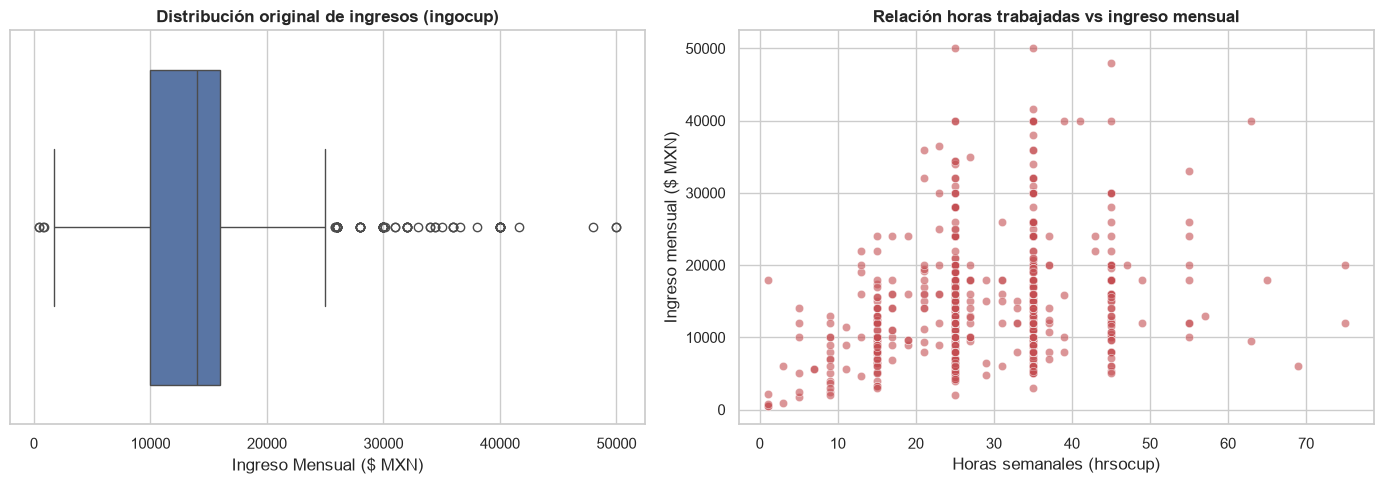

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#Diagrama de Caja (Boxplot) de salario
sns.boxplot(data=df_salario, x="ingocup", color="#4c72b0", ax=axes[0])
axes[0].set_title(
    "Distribución original de ingresos (ingocup)", fontweight="bold"
)
axes[0].set_xlabel("Ingreso Mensual ($ MXN)")

# Relación horas trabajadas vs salario mensual
sns.scatterplot(
    data=df_salario,
    x="hrsocup",
    y="ingocup",
    alpha=0.6,
    color="#c44e52",
    ax=axes[1],
)
axes[1].set_title(
    "Relación horas trabajadas vs ingreso mensual", fontweight="bold"
)
axes[1].set_xlabel("Horas semanales (hrsocup)")
axes[1].set_ylabel("Ingreso mensual ($ MXN)")

plt.tight_layout()
plt.show()

In [6]:
# Variables seleccionadas para la detección de anomalías
X_outliers = df_salario[["ingocup", "hrsocup"]].copy()

# Configuración de Isolation Forest (contaminación estimada del 2% al 3%)
iso_forest = IsolationForest(contamination=0.025, random_state=42)
df_salario["anomalia"] = iso_forest.fit_predict(X_outliers)

# 1 = Normal, -1 = Anomalía/Outlier
df_salario["es_anomalia"] = df_salario["anomalia"].map(
    {1: "Normal", -1: "Anomalía"}
)

print("Resumen de detección de anomalías:")
print(df_salario["es_anomalia"].value_counts())

Resumen de detección de anomalías:
es_anomalia
Normal      1097
Anomalía      29
Name: count, dtype: int64
